## LMVA EDA 

`Steps`
01. Dataset Structure and Coverage
02. Data Integrity & Quality
03. Sensor Structure and Activity
04. Overall Temporal Patterns
05. Daily and Hourly Activity Pattern
06. Peak-Period Analysis
07. Directional Analysis
08. Spatial Integration
09. Normalized Pedestrian Flow
10. Interactive Crowd Map

`new column add - tag`
1. `date` - out of timestamp
2. `network_count` - total pedestrian counts recorded across all sensor directions during that 3-minute interval.

 

## Conclusion

### 1. Dataset Structure and Coverage
- The dataset contains **2,400 rows and 81 columns**, covering 20–24 August 2025 at 3-minute intervals.
- The columns comprise 1 timestamp, 74 directional measurements and 6 temporal features.
- The 74 measurements represent **37 physical sensors × 2 opposite directions**.

### 2. Data Integrity and Quality
- No missing values, duplicate rows, duplicate timestamps, negative counts or timestamp gaps were found.
- All observations follow a continuous 3-minute sampling interval, and temporal features are consistent with the timestamps.
- Zero counts were retained as valid observations because they may represent genuine inactivity or potential sensor issues.

### 3. Sensor Structure and Activity
- Pedestrian activity varies substantially across sensors.
- `GASA-02-02` and `GASA-03` showed high activity, while `GASA-06` and `GVCV-09` recorded very low activity.
- `GASA-06-B` was treated as the active measurement series for the `GASA-06` location, based on our working assumption.

### 4. Overall Temporal Patterns
Daily recorded pedestrian counts were:

| Date | Total counts |
|---|---:|
| 20 Aug | 834,656 |
| 21 Aug | 945,189 |
| 22 Aug | 1,019,801 |
| 23 Aug | 1,267,072 |
| 24 Aug | 892,419 |

- **23 August was the busiest observed day**, accounting for approximately 25.6% of all recorded counts.

### 5. Daily and Hourly Activity Patterns
- Activity was highest during the afternoon and early evening, particularly between **14:00 and 18:00**.
- The busiest hour was 17:00, followed by 16:00 and 15:00.
- These patterns describe the five-day SAIL observation period and should not be generalized to typical Amsterdam activity.

### 6. Peak-Period Analysis
- The highest network-wide count was **6,887 at 16:42 on 23 August 2025**, equivalent to approximately 2,296 recorded counts per minute across the network.
- Peak intervals can be identified using the 95th-percentile threshold.
- High network-wide counts indicate elevated activity but do not independently establish unsafe crowding.

### 7. Directional Analysis
- Each physical sensor has two measurements representing opposite orientations.
- The directionality index was defined as 
`D = |c1-c2|/(c1+c2)` , ranging from 0 (balanced) to 1 (highly imbalanced).
- This helps identify directional asymmetry but does not independently establish congestion or travel direction.

### 8. Spatial Integration
- Sensor counts were combined with location metadata containing coordinates, location names and width information.
- `GASA-06-B` was mapped to the `GASA-06` location using our working assumption.
- Correct sensor matching and valid coordinates are essential for reliable spatial analysis.

### 9. Normalized Pedestrian Flow
- Pedestrian flow was calculated using effective width:

  `q= count / {effective width * 3}`

- Flow is expressed in **people per metre per minute**, enabling comparisons between locations with different effective widths.
- Flow cannot be calculated reliably when effective width is missing or invalid.

### 10. Interactive Crowd Map
- An interactive Folium map was created to visualize sensor locations and pedestrian activity.
- Marker size represents total recorded counts, while popups provide sensor information and normalized flow where available.
- The map supports spatial exploration but does not directly measure crowd density or safety.

### 11. Limitations
- The dataset covers only five days during SAIL 2025.
- Counts do not represent unique individuals or the number of people simultaneously present.
- Low or zero counts do not prove sensor failure.
- Missing effective widths and uncertain sensor mappings can limit spatial comparisons.
- Further evidence is required to assess congestion or crowd safety.

### 12. Overall Conclusion
The LVMA dataset is structurally complete and provides high-resolution pedestrian counts across 37 physical sensors. The EDA identified substantial spatial and temporal variation, with the highest recorded activity on 23 August and during the afternoon and early evening. Integrating sensor locations and effective widths enables spatial visualization and normalized flow analysis. These findings provide a foundation for further hotspot detection and crowd-management analysis, while conclusions about congestion and safety require additional context.

In [212]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import folium

In [76]:
dflm=pd.read_csv('sail_lvma.csv')
dflm.shape

(2400, 81)

In [77]:
dflm.head()

,timestamp,CMSA-GAKH-01_0,CMSA-GAKH-01_180,CMSA-GAWW-11_120,CMSA-GAWW-11_300,CMSA-GAWW-12_115,CMSA-GAWW-12_295,CMSA-GAWW-13_120,CMSA-GAWW-13_300,CMSA-GAWW-14_40,...,GVCV-13_10,GVCV-13_190,GVCV-14_90,GVCV-14_270,hour,minute,day,month,weekday,is_weekend
0,2025-08-20 00:00:00+02:00,15,4,29,33,44,28,42,37,11,...,41,40,0,0,0,0,20,8,2,0
1,2025-08-20 00:03:00+02:00,1,3,21,29,34,39,9,14,6,...,0,0,0,0,0,3,20,8,2,0
2,2025-08-20 00:06:00+02:00,5,4,35,22,29,34,33,42,14,...,0,0,0,0,0,6,20,8,2,0
3,2025-08-20 00:09:00+02:00,4,4,40,47,42,40,19,34,15,...,0,0,0,0,0,9,20,8,2,0
4,2025-08-20 00:12:00+02:00,4,11,54,59,58,33,17,33,26,...,127,57,0,0,0,12,20,8,2,0


### 1. Dataset Validation
Quick sanity checks before trusting anything: is the time axis regular, are values valid counts, are the pre-computed calendar columns consistent with the timestamp?

In [79]:

dflm["timestamp"] = pd.to_datetime(dflm["timestamp"])

time_cols = [
    "timestamp", "hour", "minute",
    "day", "month", "weekday", "is_weekend"
]

sensor_cols = [c for c in dflm.columns if c not in time_cols]

print("Shape:", dflm.shape)
print("Time:", dflm["timestamp"].min(), "→", dflm["timestamp"].max())
print("Sensors:", len(sensor_cols))
print("Missing:", dflm.isna().sum().sum())
print("Duplicate timestamps:", dflm["timestamp"].duplicated().sum())
print("Negative counts:", (dflm[sensor_cols] < 0).sum().sum())

Shape: (2400, 81)
Time: 2025-08-20 00:00:00+02:00 → 2025-08-24 23:57:00+02:00
Sensors: 74
Missing: 0
Duplicate timestamps: 0
Negative counts: 0


In [87]:
dflm[sensor_cols].dtypes.value_counts()

# all sensor column values are integers.

int64    74
Name: count, dtype: int64

In [24]:
dflm["timestamp"].dt.date.value_counts().sort_index()

timestamp
2025-08-20    480
2025-08-21    480
2025-08-22    480
2025-08-23    480
2025-08-24    480
Name: count, dtype: int64

`Data overview Container`

In [80]:
overview = {
    "Rows": dflm.shape[0],
    "Columns": dflm.shape[1],
    "Sensor-direction columns": 74,
    "Temporal columns": 6,
}

overview

{'Rows': 2400,
 'Columns': 81,
 'Sensor-direction columns': 74,
 'Temporal columns': 6}

### 2. Data Integrity & Quality

In [84]:
sensor_cols = [
    c for c in dflm.columns
    if c not in [
        "timestamp",
        "hour",
        "minute",
        "day",
        "month",
        "weekday",
        "is_weekend"
    ]
]

(dflm[sensor_cols] < 0).sum().sum()

# no -ve pedestrian counts.

np.int64(0)

In [91]:
# all hours should match with timestamp range.
# LHS fetched the hours out of the timestamp and compare it with hour column,
# doing the same for rest of time columns.

print((dflm["timestamp"].dt.hour != dflm["hour"]).sum())
print((dflm["timestamp"].dt.minute != dflm["minute"]).sum())
print((dflm["timestamp"].dt.day != dflm["day"]).sum())
print((dflm["timestamp"].dt.month != dflm["month"]).sum())
print((dflm["timestamp"].dt.weekday != dflm["weekday"]).sum())

0
0
0
0
0


In [92]:
print(dflm["hour"].min(), dflm["hour"].max())
print(dflm["minute"].min(), dflm["minute"].max())
print(dflm["day"].min(), dflm["day"].max())
print(dflm["month"].unique())
print(dflm["weekday"].unique())
print(dflm["is_weekend"].unique())

0 23
0 57
20 24
[8]
[2 3 4 5 6]
[0 1]


### 3. Temporal Structure

In [94]:
# lets create a date column for easier further analysis and visualisation
dflm["date"] = dflm["timestamp"].dt.date
dflm["network_count"] = dflm[sensor_cols].sum(axis=1)


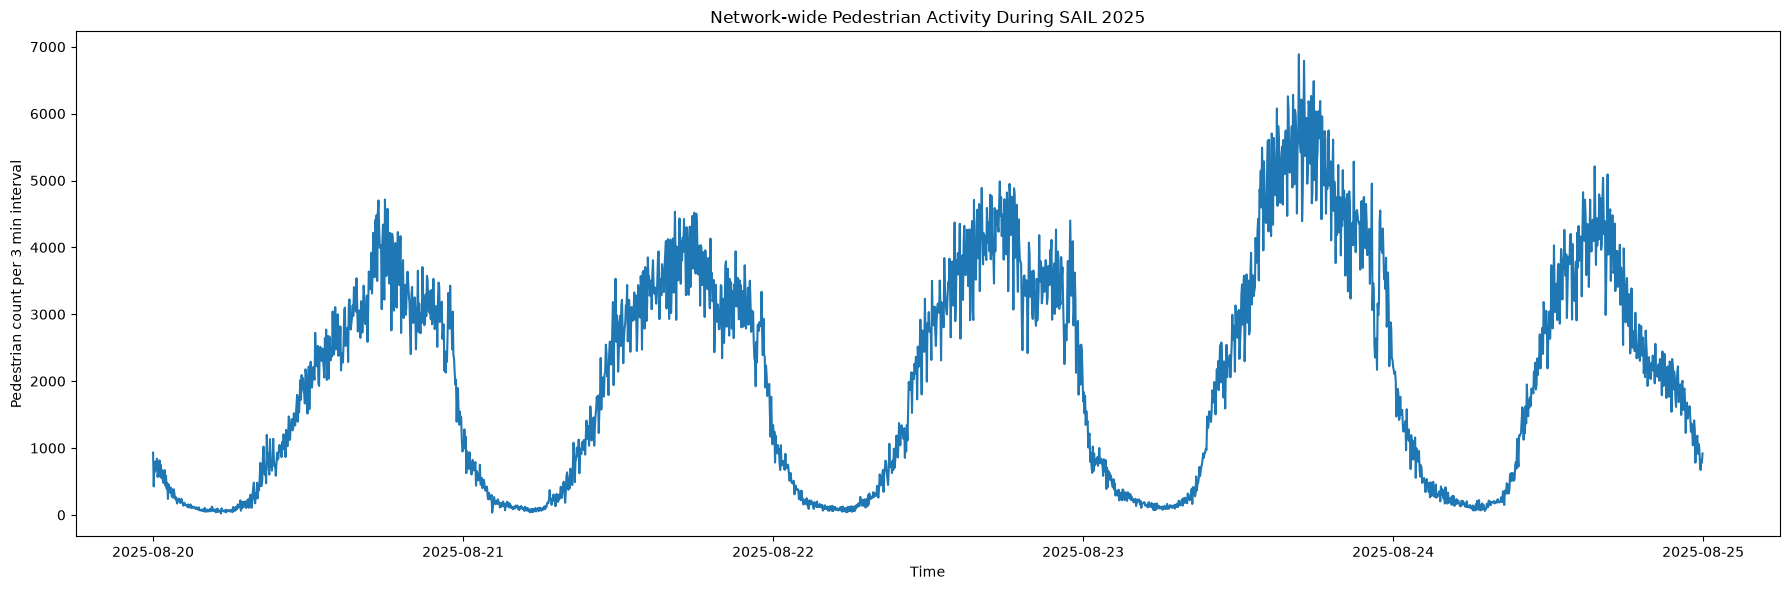

In [108]:
plt.figure(figsize=(18, 6))

plt.plot(
    dflm["timestamp"],
    dflm["network_count"]
)

plt.xlabel("Time")
plt.ylabel("Pedestrian count per 3 min interval")
plt.title("Network-wide Pedestrian Activity During SAIL 2025")

plt.tight_layout()
plt.show()

`ask question`
- clear daily cycles?
- does activity disapper at night??
- when does it peak?
- are some days visibly busier?

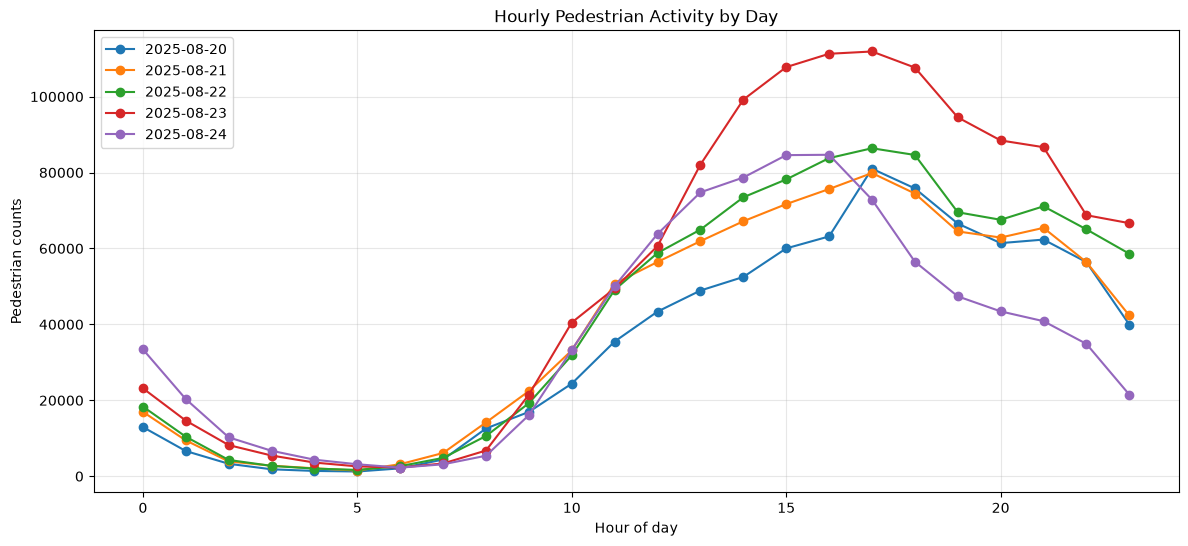

In [107]:
# this is the hourly aggreagate pedestrians counts.

hourly = (
    dflm.set_index("timestamp")["network_count"]
       .resample("1h")
       .sum()
       .reset_index()
)

hourly["date"] = hourly["timestamp"].dt.date
hourly["hour"] = hourly["timestamp"].dt.hour

plt.figure(figsize=(14, 6))

for date, group in hourly.groupby("date"):
    plt.plot(
        group["hour"],
        group["network_count"],
        marker="o",
        label=str(date)
    )

plt.xlabel("Hour of day")
plt.ylabel("Pedestrian counts")
plt.title("Hourly Pedestrian Activity by Day")
plt.legend()
plt.grid(alpha=0.3)


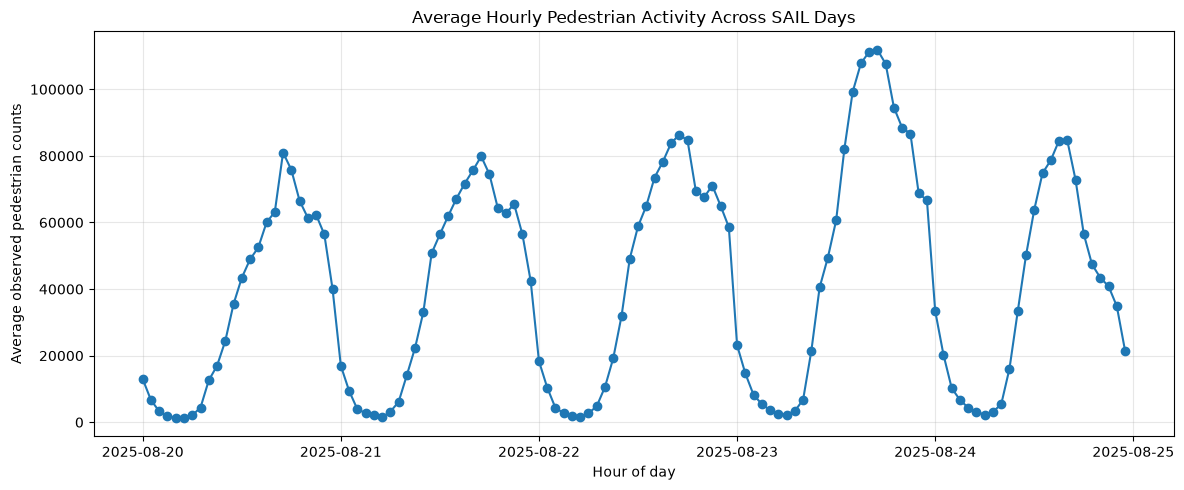

In [111]:
mean_hourly = (
    hourly.groupby("timestamp")["network_count"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    mean_hourly.index,
    mean_hourly.values,
    marker="o"
)

plt.xlabel("Hour of day")
plt.ylabel("Average observed pedestrian counts")
plt.title("Average Hourly Pedestrian Activity Across SAIL Days")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

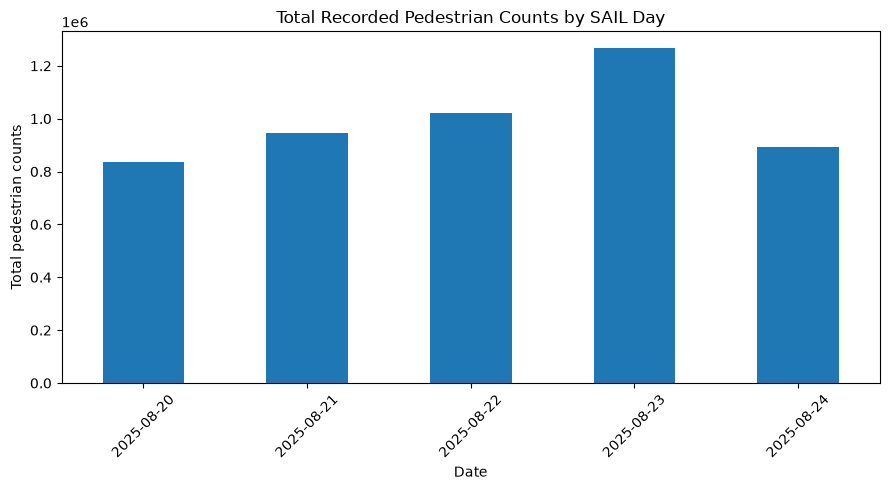

In [113]:
daily = (
    dflm.groupby("date")["network_count"]
    .sum()
)

plt.figure(figsize=(9, 5))

daily.plot(kind="bar")

plt.xlabel("Date")
plt.ylabel("Total pedestrian counts")
plt.title("Total Recorded Pedestrian Counts by SAIL Day")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

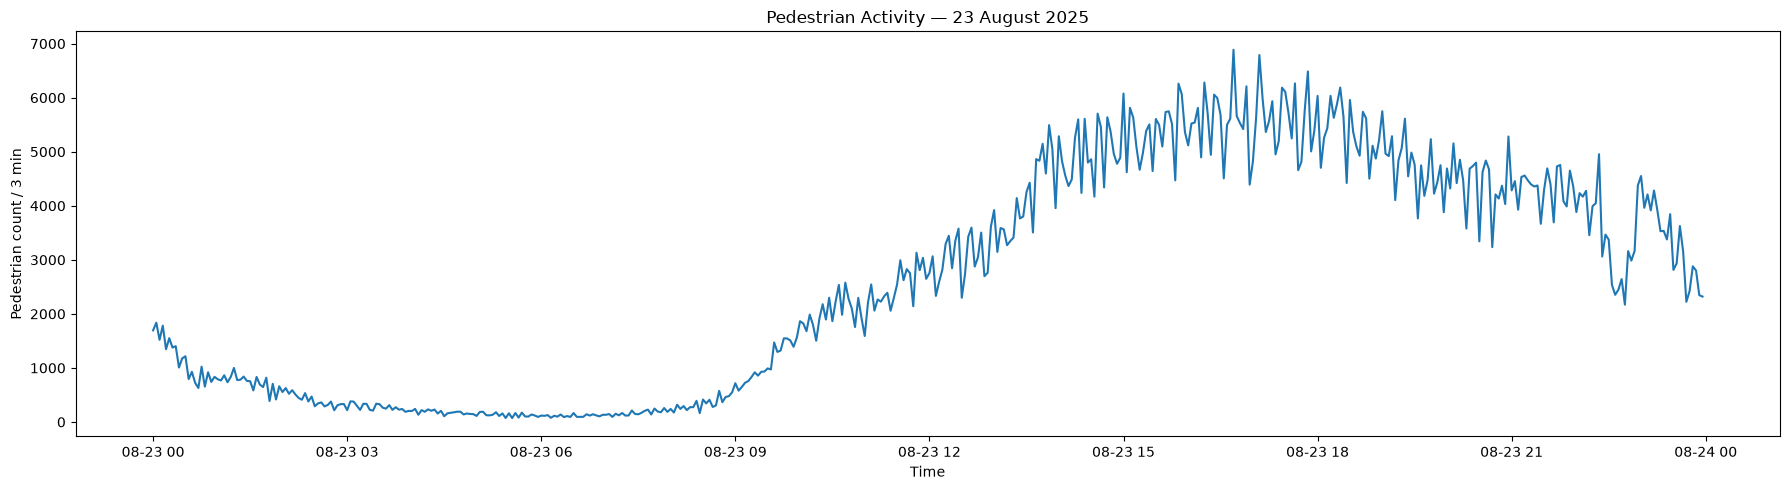

In [115]:
# lets explore the day-23 bit more

day23 = dflm[
    dflm["date"] == pd.Timestamp("2025-08-23").date()
]

plt.figure(figsize=(18, 5))

plt.plot(
    day23["timestamp"],
    day23["network_count"]
)

plt.xlabel("Time")
plt.ylabel("Pedestrian count / 3 min")
plt.title("Pedestrian Activity — 23 August 2025")

plt.tight_layout()
plt.show()

### 4 Understanding Sensors
- `CMSA-GAWW-11_120`
- `CMSA-GAWW-11_300`\
means -> Physical Sensor is `CMSA-GAWW-11` with direction 1: `120 deg` & direction 2: `300 deg`

In [116]:
time_cols = [
    "timestamp",
    "hour",
    "minute",
    "day",
    "month",
    "weekday",
    "is_weekend",
    "date", # 2 columns get added while doing above analysis
    "network_count"
]

sensor_cols = [
    c for c in dflm.columns
    if c not in time_cols
]

print("Sensor-direction columns:", len(sensor_cols))

Sensor-direction columns: 74


`metadata for sensors`\
helpful for later on!!!

In [118]:
sensor_meta = pd.DataFrame({
    "column": sensor_cols
})

sensor_meta[["sensor", "direction"]] = (
    sensor_meta["column"]
    .str.rsplit("_", n=1, expand=True)
)

sensor_meta["direction"] = sensor_meta["direction"].astype(int)

sensor_meta

,column,sensor,direction
0,CMSA-GAKH-01_0,CMSA-GAKH-01,0
1,CMSA-GAKH-01_180,CMSA-GAKH-01,180
2,CMSA-GAWW-11_120,CMSA-GAWW-11,120
3,CMSA-GAWW-11_300,CMSA-GAWW-11,300
4,CMSA-GAWW-12_115,CMSA-GAWW-12,115
...,...,...,...
69,GVCV-11_230,GVCV-11,230
70,GVCV-13_10,GVCV-13,10
71,GVCV-13_190,GVCV-13,190
72,GVCV-14_90,GVCV-14,90


In [128]:
sensor_counts = (
    sensor_meta
    .groupby("sensor")
    .size()
)
print(sensor_meta["sensor"].nunique())
print(sensor_counts.value_counts())
print(sensor_counts[sensor_counts != 2]) # hence no exception, all sensors have 2 directions.

37
2    37
Name: count, dtype: int64
Series([], dtype: int64)


In [131]:
sensor_table = (
    sensor_meta
    .groupby("sensor")
    .agg(
        directions=("direction", list),
        n_directions=("direction", "count")
    )
    .reset_index()
)

sensor_table.head()

,sensor,directions,n_directions
0,CMSA-GAKH-01,"[0, 180]",2
1,CMSA-GAWW-11,"[120, 300]",2
2,CMSA-GAWW-12,"[115, 295]",2
3,CMSA-GAWW-13,"[120, 300]",2
4,CMSA-GAWW-14,"[40, 220]",2


             120°
               ↑
               │
               │
          [ SENSOR ]
               │
               │
               ↓
             300°

two measurements from the same physical location, just directions are apart from 180 deg.

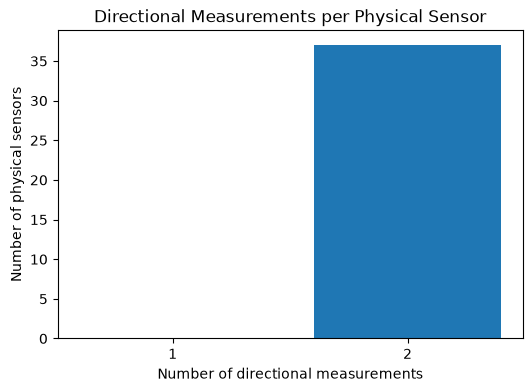

In [135]:
sensor_counts.plot(
    kind="hist",
    bins=[0.5, 1.5, 2.5],
    rwidth=0.8,
    figsize=(6, 4)
)

plt.xlabel("Number of directional measurements")
plt.ylabel("Number of physical sensors")
plt.title("Directional Measurements per Physical Sensor")
plt.xticks([1, 2])
plt.show()

# all physical sensors have 2 directional measurements, hence no exception in the dataset.

### 5 Pedestrain Count Distributions

In [136]:
all_counts = dflm[sensor_cols].stack()

all_counts.describe()

count    177600.000000
mean         27.923069
std          53.021903
min           0.000000
25%           0.000000
50%           5.000000
75%          32.000000
max         718.000000
dtype: float64

> 75% of all 177,600 sensor-direction-time observations have a pedestrian count of 32 or less.

In [137]:
print("Mean:", all_counts.mean())
print("Median:", all_counts.median())
print("Skewness:", all_counts.skew())

Mean: 27.923068693693693
Median: 5.0
Skewness: 3.546255809363178


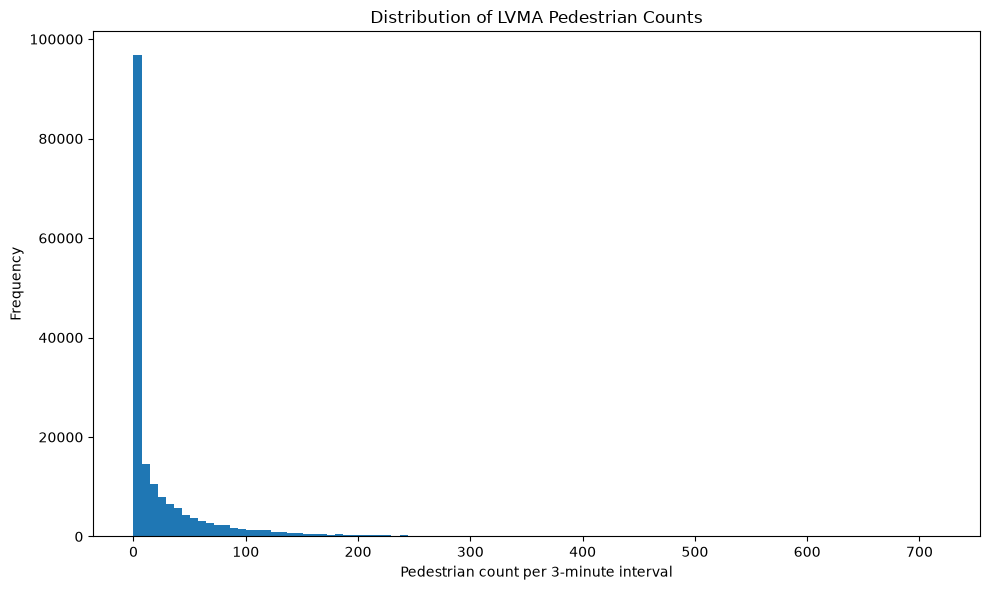

In [171]:
plt.figure(figsize=(10, 6))

plt.hist(
    all_counts,
    bins=100
)

plt.xlabel("Pedestrian count per 3-minute interval")
plt.ylabel("Frequency")
plt.title("Distribution of LVMA Pedestrian Counts")

plt.tight_layout()
plt.show()

> there are so many 0s as a count, and the count of 200+ is very low as u can see, as count increases frequency 
> decreaases.

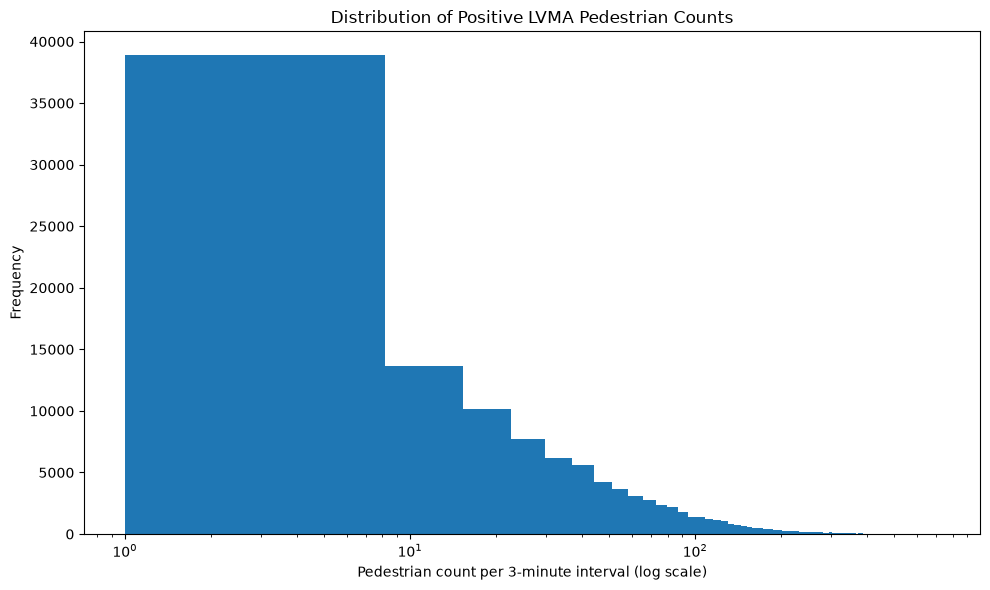

In [172]:
positive_counts = all_counts[all_counts > 0]

plt.figure(figsize=(10, 6))

plt.hist(
    positive_counts,
    bins=100
)

plt.xscale("log")

plt.xlabel("Pedestrian count per 3-minute interval (log scale)")
plt.ylabel("Frequency")
plt.title("Distribution of Positive LVMA Pedestrian Counts")

plt.tight_layout()
plt.show()

In [173]:
sensor_stats = dflm[sensor_cols].describe().T

sensor_stats["median"] = dflm[sensor_cols].median()
sensor_stats["mean"] = dflm[sensor_cols].mean()
sensor_stats["std"] = dflm[sensor_cols].std()
sensor_stats["skewness"] = dflm[sensor_cols].skew()

sensor_stats[
    ["mean", "median", "std", "min", "max", "skewness"]
].sort_values("mean", ascending=False).head(10)

,mean,median,std,min,max,skewness
GASA-02-02_135,126.797083,57.5,146.770072,0.0,599.0,1.023170
GASA-03_105,110.038333,49.5,124.482593,0.0,542.0,0.971429
GASA-03_285,103.021667,35.5,120.220245,0.0,718.0,1.038532
GASA-02-01_315,95.525000,19.5,121.908521,0.0,588.0,1.095841
GACM-04_230,81.325833,65.0,75.470229,0.0,318.0,0.590303
GASA-04_135,64.394167,48.5,64.901725,0.0,291.0,0.858228
CMSA-GAWW-21_300,59.276667,55.0,49.511462,0.0,387.0,0.503642
CMSA-GAWW-21_120,58.222917,49.0,50.850408,0.0,225.0,0.431586
CMSA-GAKH-01_0,57.513750,17.0,69.204386,0.0,266.0,0.992690
GACM-04_50,53.148333,40.0,47.832673,0.0,212.0,0.743204


Some sensor directions experience much more pedestrian movement than others.
That means later:
>We should be careful about comparing raw counts directly between sensors.

A count of 200 may be huge at one location but normal at another.

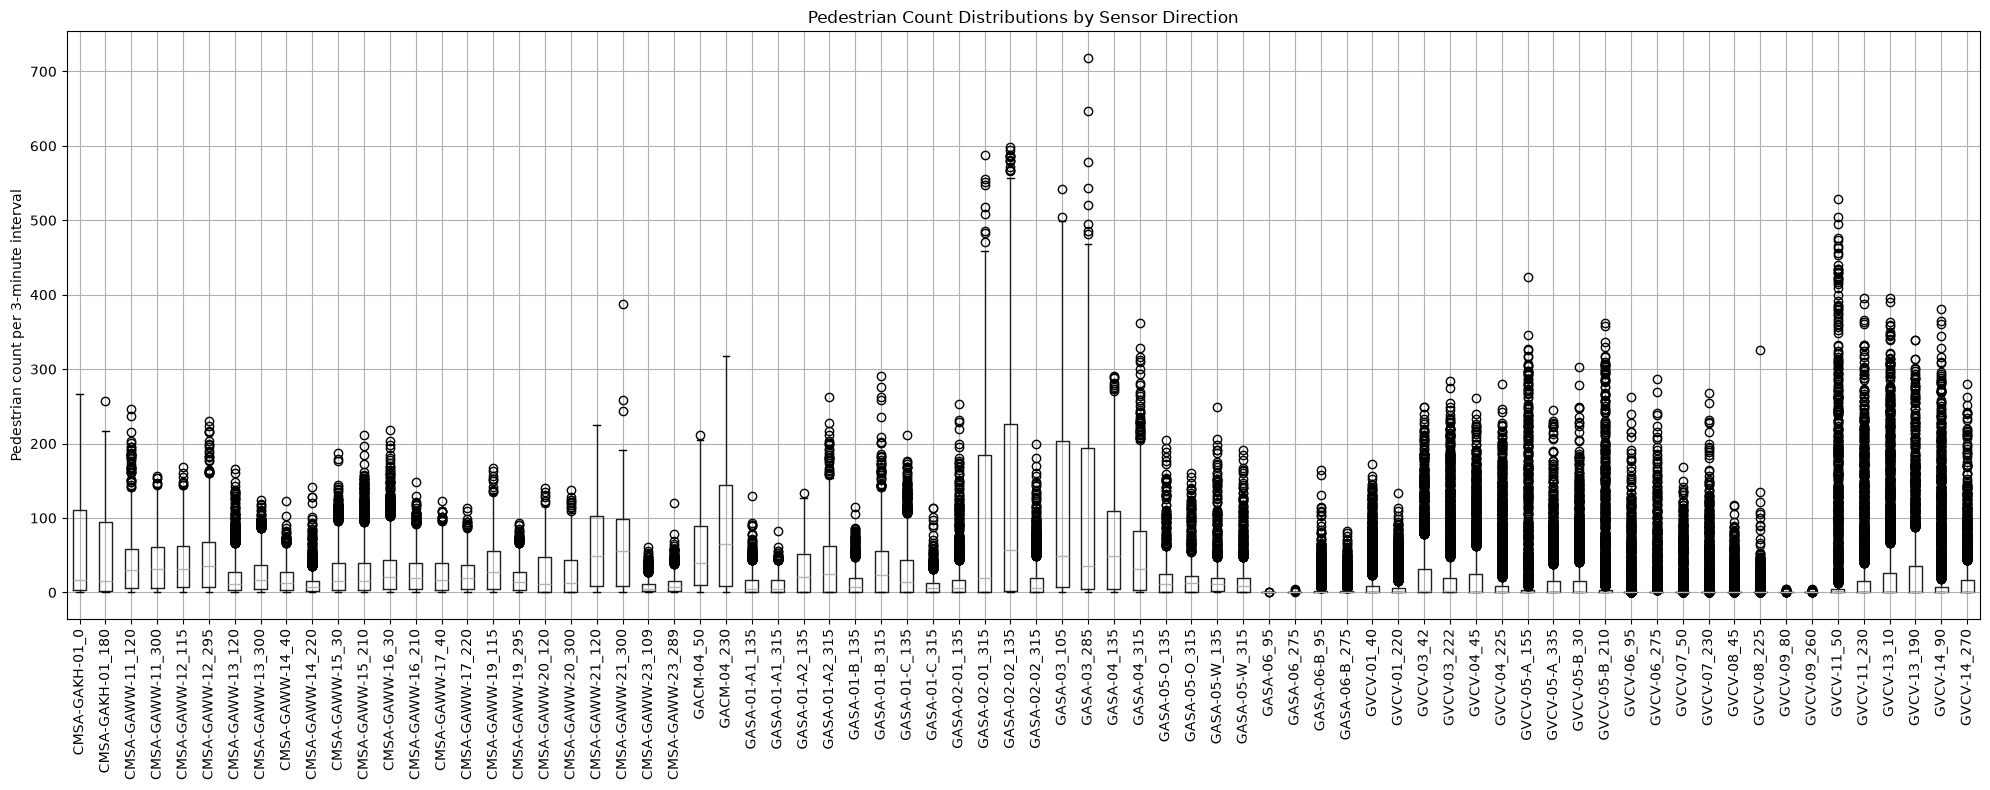

In [174]:
plt.figure(figsize=(20, 8))

dflm[sensor_cols].boxplot(
    rot=90
)

plt.ylabel("Pedestrian count per 3-minute interval")
plt.title("Pedestrian Count Distributions by Sensor Direction")

plt.tight_layout()
plt.show()

>The box is small → most observations are relatively concentrated.\
>The median is low → typical pedestrian count is low.\
>There are many circles above → occasionally the sensor experiences much higher pedestrian counts.

`Daily & Hourly Patterns`

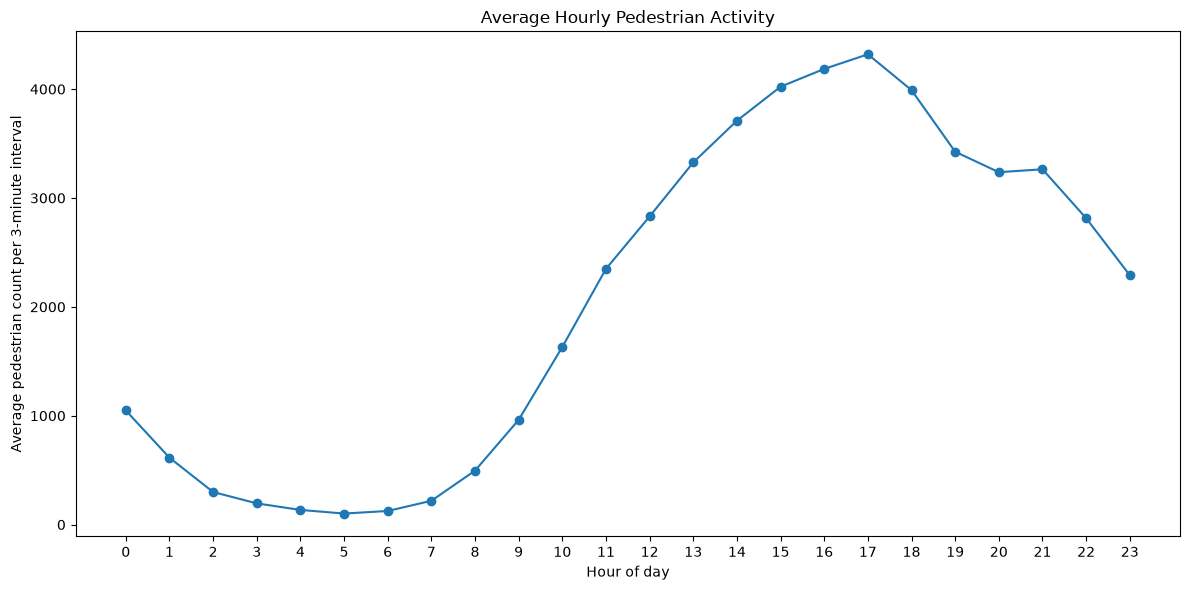

In [170]:
hourly_profile = (
    dflm.groupby("hour")["network_count"]
    .mean()
)

hourly_profile


plt.figure(figsize=(12, 6))

plt.plot(
    hourly_profile.index,
    hourly_profile.values,
    marker="o"
)

plt.xlabel("Hour of day")
plt.ylabel("Average pedestrian count per 3-minute interval")
plt.title("Average Hourly Pedestrian Activity")

plt.xticks(range(24))

plt.tight_layout()
plt.show()

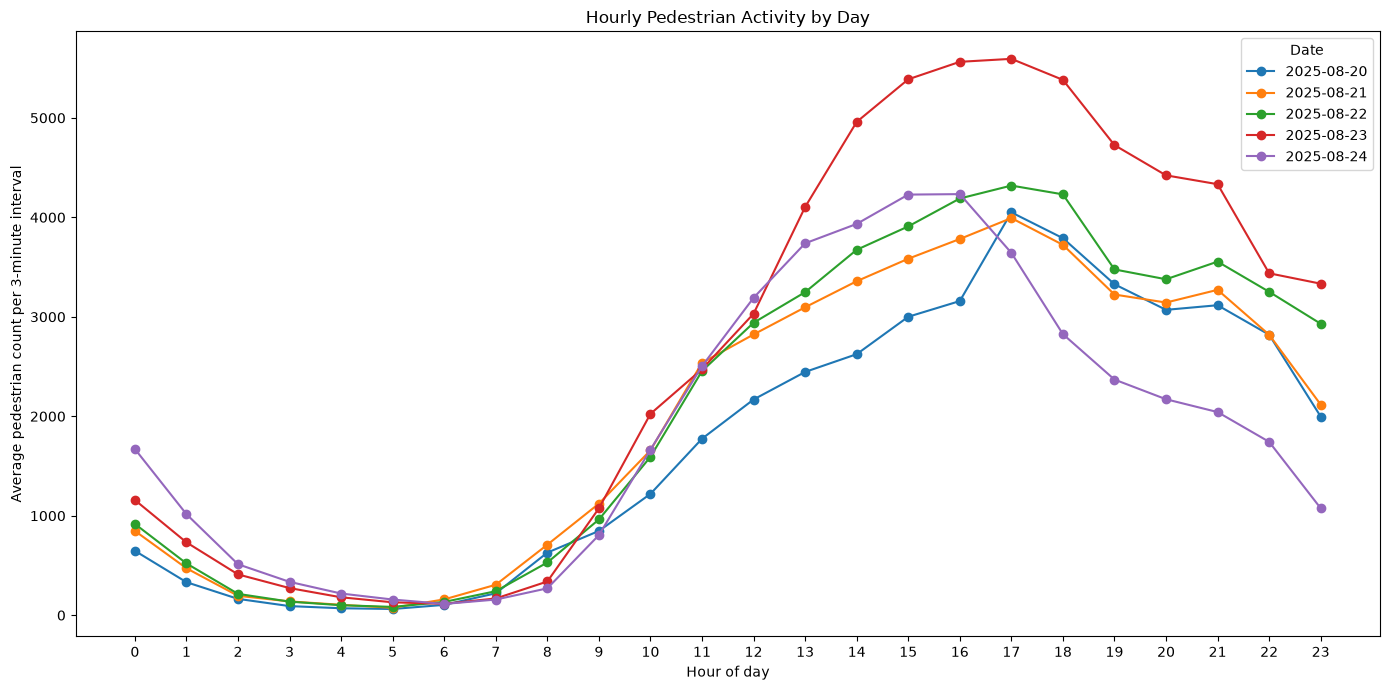

In [175]:
daily_hourly = (
    dflm.groupby(["date", "hour"])["network_count"]
    .mean()
    .reset_index()
)

daily_hourly.head()

plt.figure(figsize=(14, 7))

for date in daily_hourly["date"].unique():

    data = daily_hourly[
        daily_hourly["date"] == date
    ]

    plt.plot(
        data["hour"],
        data["network_count"],
        marker="o",
        label=str(date)
    )

plt.xlabel("Hour of day")
plt.ylabel("Average pedestrian count per 3-minute interval")
plt.title("Hourly Pedestrian Activity by Day")

plt.xticks(range(24))
plt.legend(title="Date")

plt.tight_layout()
plt.show()

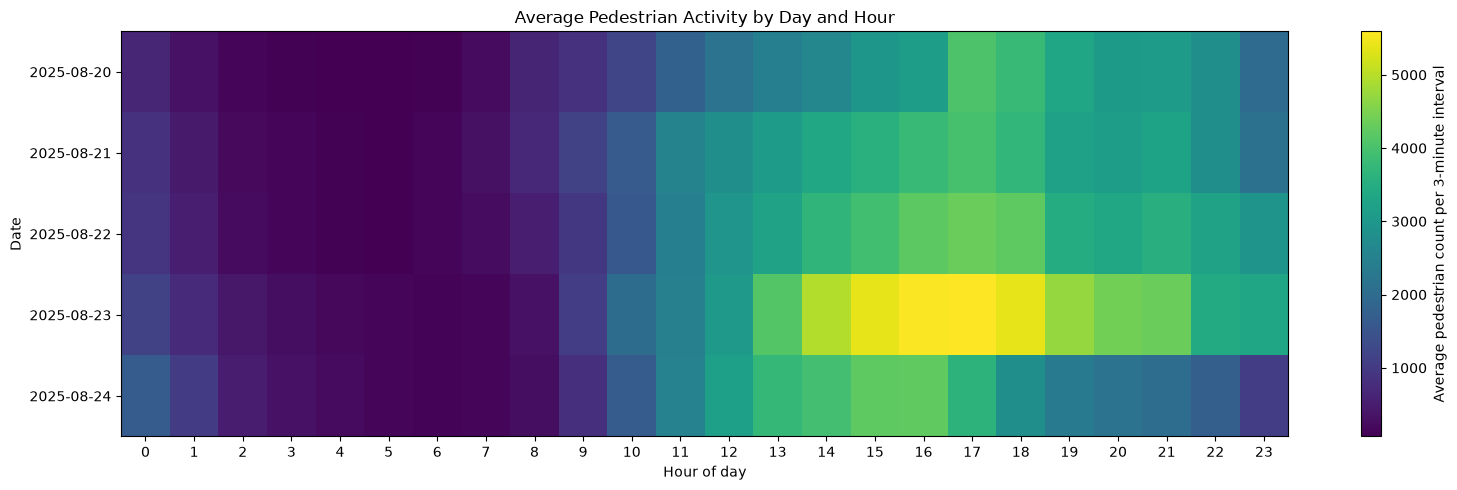

In [176]:
day_hour = (
    dflm.pivot_table(
        index="date",
        columns="hour",
        values="network_count",
        aggfunc="mean"
    )
)

day_hour
plt.figure(figsize=(16, 5))

plt.imshow(
    day_hour,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(
    label="Average pedestrian count per 3-minute interval"
)

plt.xlabel("Hour of day")
plt.ylabel("Date")
plt.title("Average Pedestrian Activity by Day and Hour")

plt.xticks(range(24))
plt.yticks(
    range(len(day_hour)),
    [str(date) for date in day_hour.index]
)

plt.tight_layout()
plt.show()

In [178]:
# Busiest Day and its hours

hourly_profile.sort_values(
    ascending=False
).head(10)

day_hour_long = (
    day_hour
    .stack()
    .reset_index(name="average_count")
    .sort_values("average_count", ascending=False)
)

day_hour_long.head(10)

,date,hour,average_count
89,2025-08-23,17,5593.65
88,2025-08-23,16,5563.70
87,2025-08-23,15,5388.00
90,2025-08-23,18,5382.20
86,2025-08-23,14,4959.65
91,2025-08-23,19,4726.20
92,2025-08-23,20,4422.35
93,2025-08-23,21,4333.40
65,2025-08-22,17,4319.50
112,2025-08-24,16,4233.55


### 6. Peak Period Analysis

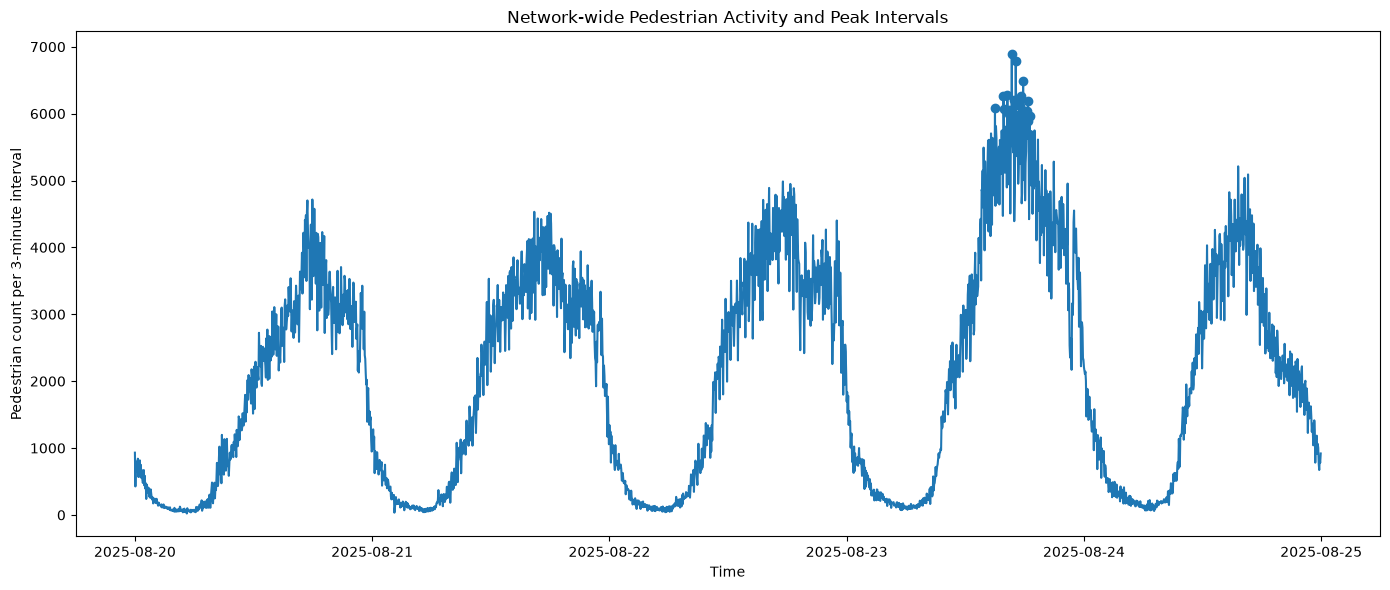

In [179]:
peak_intervals = (
    dflm[
        ["timestamp", "network_count"]
    ]
    .sort_values("network_count", ascending=False)
    .head(20)
)

peak_intervals

plt.figure(figsize=(14, 6))

plt.plot(
    dflm["timestamp"],
    dflm["network_count"]
)

plt.scatter(
    peak_intervals["timestamp"],
    peak_intervals["network_count"]
)

plt.xlabel("Time")
plt.ylabel("Pedestrian count per 3-minute interval")
plt.title("Network-wide Pedestrian Activity and Peak Intervals")

plt.tight_layout()
plt.show()

In [182]:
peak_threshold = dflm["network_count"].quantile(0.95)

print("95th percentile:", peak_threshold)

peak_periods = dflm[
    dflm["network_count"] >= peak_threshold
][
    ["timestamp", "network_count"]
].copy()

peak_periods.sort_values(
    "network_count",
    ascending=False
).head(10)

95th percentile: 4754.049999999999


,timestamp,network_count
1774,2025-08-23 16:42:00+02:00,6887
1782,2025-08-23 17:06:00+02:00,6789
1797,2025-08-23 17:51:00+02:00,6486
1765,2025-08-23 16:15:00+02:00,6280
1793,2025-08-23 17:39:00+02:00,6264
1757,2025-08-23 15:51:00+02:00,6259
1778,2025-08-23 16:54:00+02:00,6210
1807,2025-08-23 18:21:00+02:00,6188
1789,2025-08-23 17:27:00+02:00,6185
1790,2025-08-23 17:30:00+02:00,6108


### 6. Sensor Activity / Coverage
>Which sensors are actually active, and are some sensors barely recording anything?

In [144]:
sensor_activity = pd.DataFrame({
    "total_count": dflm[sensor_cols].sum(),
    "mean_count": dflm[sensor_cols].mean(),
    "median_count": dflm[sensor_cols].median(),
    "zero_count": (dflm[sensor_cols] == 0).sum(),
    "zero_rate": (dflm[sensor_cols] == 0).mean(),
    "min_count": dflm[sensor_cols].min(),
    "max_count": dflm[sensor_cols].max()
})

sensor_activity["active_rate"] = 1 - sensor_activity["zero_rate"]

sensor_activity = sensor_activity.sort_values(
    "total_count",
    ascending=False
)

sensor_activity.head(10)

,total_count,mean_count,median_count,zero_count,zero_rate,min_count,max_count,active_rate
GASA-02-02_135,304313,126.797083,57.5,510,0.212500,0,599,0.787500
GASA-03_105,264092,110.038333,49.5,273,0.113750,0,542,0.886250
GASA-03_285,247252,103.021667,35.5,327,0.136250,0,718,0.863750
GASA-02-01_315,229260,95.525000,19.5,634,0.264167,0,588,0.735833
GACM-04_230,195182,81.325833,65.0,103,0.042917,0,318,0.957083
GASA-04_135,154546,64.394167,48.5,368,0.153333,0,291,0.846667
CMSA-GAWW-21_300,142264,59.276667,55.0,67,0.027917,0,387,0.972083
CMSA-GAWW-21_120,139735,58.222917,49.0,73,0.030417,0,225,0.969583
CMSA-GAKH-01_0,138033,57.513750,17.0,172,0.071667,0,266,0.928333
GACM-04_50,127556,53.148333,40.0,39,0.016250,0,212,0.983750


> `total_count`  total pedestrian counts recorded over 5 days.\
> `mean_count`	Average count per 3-min interval\
> `median_count`	Typical count per interval\
> `zero_count`	Number of intervals with zero\
> `zero_rate`	Fraction of intervals with zero\
> `active_rate`	Fraction of intervals with >0\
> `min_count`	Minimum observed count\
> `max_count`	Maximum observed count

In [145]:
# least active sensor

sensor_activity.sort_values(
    "zero_rate",
    ascending=False
).head(10)

,total_count,mean_count,median_count,zero_count,zero_rate,min_count,max_count,active_rate
GASA-06_95,3,0.001250,0.0,2397,0.998750,0,1,0.001250
GASA-06_275,10,0.004167,0.0,2396,0.998333,0,4,0.001667
GVCV-09_80,57,0.023750,0.0,2369,0.987083,0,4,0.012917
GVCV-09_260,56,0.023333,0.0,2369,0.987083,0,4,0.012917
GVCV-08_225,6929,2.887083,0.0,1937,0.807083,0,326,0.192917
GVCV-07_230,20241,8.433750,0.0,1906,0.794167,0,268,0.205833
GVCV-07_50,14903,6.209583,0.0,1891,0.787917,0,168,0.212083
GVCV-08_45,10499,4.374583,0.0,1874,0.780833,0,117,0.219167
GVCV-06_95,17739,7.391250,0.0,1800,0.750000,0,262,0.250000
GVCV-06_275,19374,8.072500,0.0,1774,0.739167,0,287,0.260833


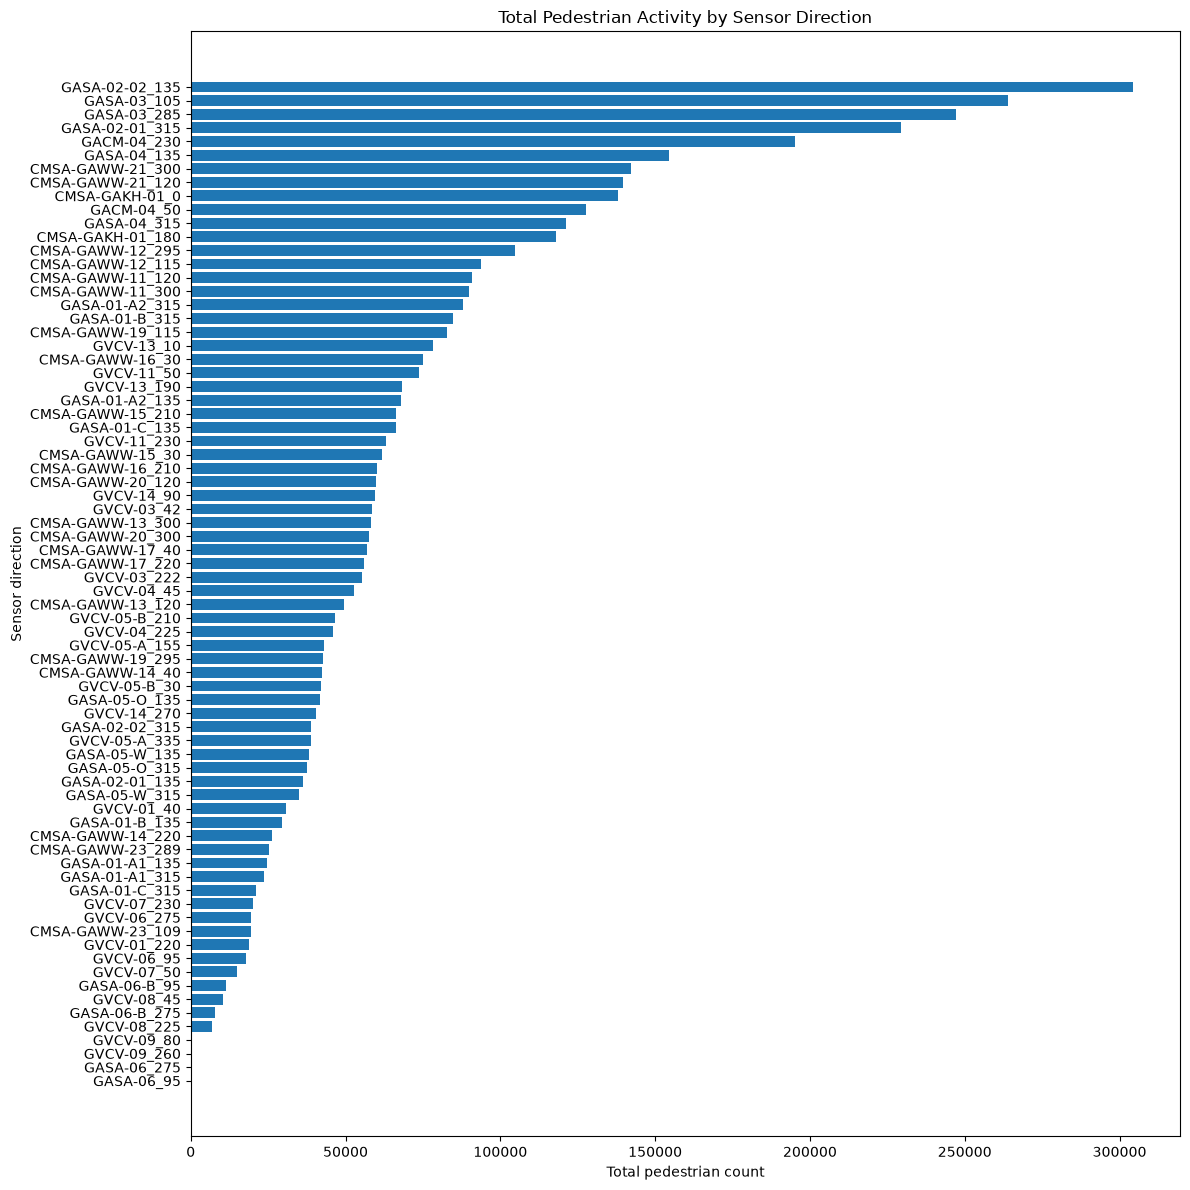

In [146]:
activity_sorted = sensor_activity.sort_values("total_count")

plt.figure(figsize=(12, 12))

plt.barh(
    activity_sorted.index,
    activity_sorted["total_count"]
)

plt.xlabel("Total pedestrian count")
plt.ylabel("Sensor direction")
plt.title("Total Pedestrian Activity by Sensor Direction")

plt.tight_layout()
plt.show()

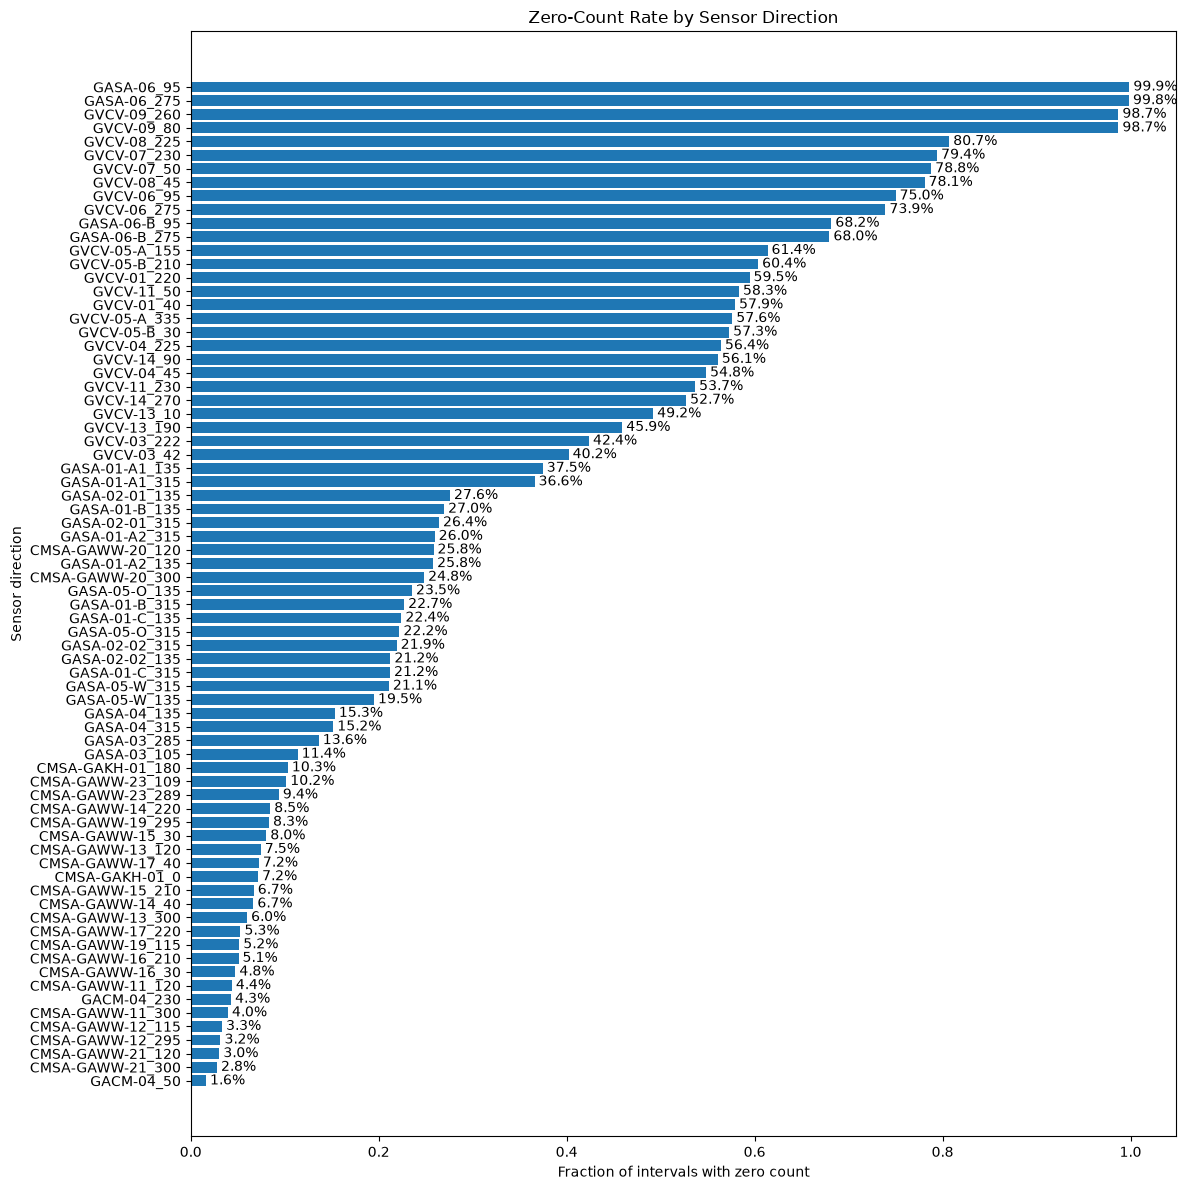

In [151]:
zero_sorted = sensor_activity.sort_values("zero_rate")

plt.figure(figsize=(12, 12))

plt.barh(
    zero_sorted.index,
    zero_sorted["zero_rate"]
)

for i, v in enumerate(zero_sorted["zero_rate"]):
    plt.text(v, i, f" {v:.1%}", va="center")

plt.xlabel("Fraction of intervals with zero count")
plt.ylabel("Sensor direction")
plt.title("Zero-Count Rate by Sensor Direction")

plt.tight_layout()
plt.show()

We need to determine whether these zeros represent:
- genuinely no pedestrians,
- low activity,
- inactive sensors,
- sensor coverage issues,
- or some combination.



### 7. Directional Analysis
Now we use the fact established in Section 04:
> Each physical sensor has two opposite directional measurements.

So instead of looking at each direction independently, we want to understand:
1. How much traffic goes in each direction?
2. Is movement balanced between the two directions?
3. Are some locations strongly directional?
4. Does directionality change over time?

`directional analysis`
- for each sensor we have two directions so,\
`total = dir1 + dir2`
`share1 = (dir1)/(total)`

we can measure the directionality using:
> directionality index: |d1-d2| / (d1+d2)

>0	Perfectly balanced\
>0.1	Very balanced\
>0.5	Noticeable directional imbalance\
>0.9	Very strongly directional\
>1.0	Almost/all movement in one direction


In [164]:
directional_summary = []

for sensor in sensor_meta["sensor"].unique():

    directions = sensor_meta.loc[
        sensor_meta["sensor"] == sensor,
        "column"
    ].tolist()

    d1, d2 = directions

    total_d1 = dflm[d1].sum()
    total_d2 = dflm[d2].sum()

    total = total_d1 + total_d2

    directional_summary.append({
        "sensor": sensor,
        "direction_1": d1,
        "direction_2": d2,
        "count_1": total_d1,
        "count_2": total_d2,
        "total_count": total,
        "share_1": total_d1 / total if total > 0 else np.nan,
        "share_2": total_d2 / total if total > 0 else np.nan
    })

directional_summary = pd.DataFrame(directional_summary)

directional_summary.head()

,sensor,direction_1,direction_2,count_1,count_2,total_count,share_1,share_2
0,CMSA-GAKH-01,CMSA-GAKH-01_0,CMSA-GAKH-01_180,138033,118032,256065,0.539055,0.460945
1,CMSA-GAWW-11,CMSA-GAWW-11_120,CMSA-GAWW-11_300,90817,90001,180818,0.502256,0.497744
2,CMSA-GAWW-12,CMSA-GAWW-12_115,CMSA-GAWW-12_295,93651,104826,198477,0.471848,0.528152
3,CMSA-GAWW-13,CMSA-GAWW-13_120,CMSA-GAWW-13_300,49359,58136,107495,0.459175,0.540825
4,CMSA-GAWW-14,CMSA-GAWW-14_40,CMSA-GAWW-14_220,42439,26189,68628,0.618392,0.381608


In [165]:
directional_summary["directionality_index"] = (
    abs(
        directional_summary["count_1"]
        - directional_summary["count_2"]
    )
    / directional_summary["total_count"]
)

def classify_imbalance(x):
    if x == 0:
        return "Perfectly balanced"
    elif x <= 0.1:
        return "Very balanced"
    elif x <= 0.5:
        return "Noticeable directional imbalance"
    elif x <= 0.9:
        return "Very strongly directional"
    else:
        return "Almost/all movement in one direction"

directional_summary["imbalance"] = (
    directional_summary["directionality_index"]
    .apply(classify_imbalance)
)

directional_summary.sort_values(
    "directionality_index",
    ascending=False
).head(10)

,sensor,direction_1,direction_2,count_1,count_2,total_count,share_1,share_2,directionality_index,imbalance
18,GASA-02-02,GASA-02-02_135,GASA-02-02_315,304313,38965,343278,0.886491,0.113509,0.772983,Very strongly directional
17,GASA-02-01,GASA-02-01_135,GASA-02-01_315,36158,229260,265418,0.136230,0.863770,0.727539,Very strongly directional
23,GASA-06,GASA-06_95,GASA-06_275,3,10,13,0.230769,0.769231,0.538462,Very strongly directional
16,GASA-01-C,GASA-01-C_135,GASA-01-C_315,66263,21206,87469,0.757560,0.242440,0.515120,Very strongly directional
15,GASA-01-B,GASA-01-B_135,GASA-01-B_315,29452,84641,114093,0.258140,0.741860,0.483719,Noticeable directional imbalance
8,CMSA-GAWW-19,CMSA-GAWW-19_115,CMSA-GAWW-19_295,82717,42596,125313,0.660083,0.339917,0.320166,Noticeable directional imbalance
25,GVCV-01,GVCV-01_40,GVCV-01_220,30858,18851,49709,0.620773,0.379227,0.241546,Noticeable directional imbalance
4,CMSA-GAWW-14,CMSA-GAWW-14_40,CMSA-GAWW-14_220,42439,26189,68628,0.618392,0.381608,0.236784,Noticeable directional imbalance
12,GACM-04,GACM-04_50,GACM-04_230,127556,195182,322738,0.395231,0.604769,0.209538,Noticeable directional imbalance
32,GVCV-08,GVCV-08_45,GVCV-08_225,10499,6929,17428,0.602421,0.397579,0.204843,Noticeable directional imbalance


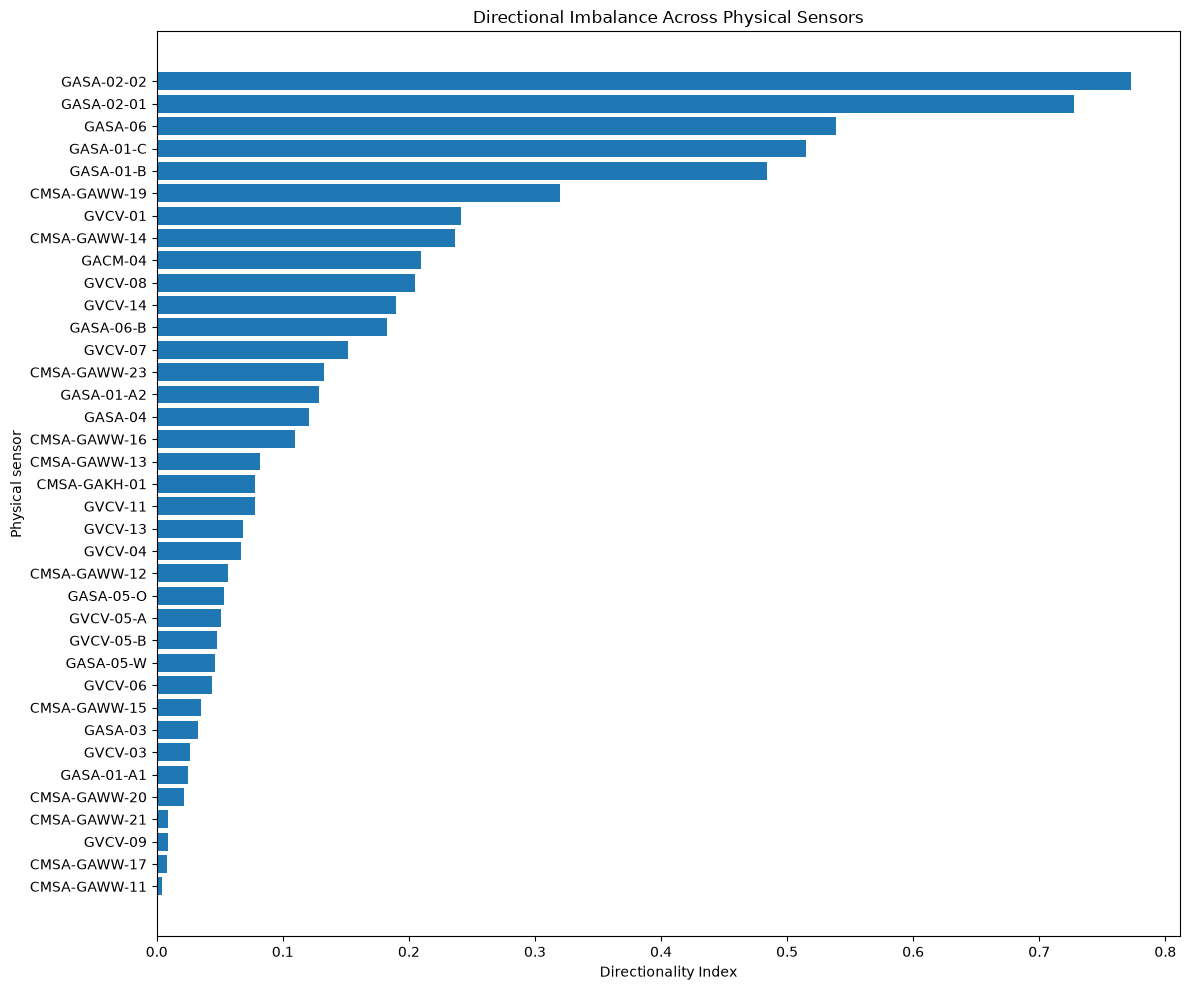

In [166]:
directional_plot = directional_summary.sort_values(
    "directionality_index"
)

plt.figure(figsize=(12, 10))

plt.barh(
    directional_plot["sensor"],
    directional_plot["directionality_index"]
)

plt.xlabel("Directionality Index")
plt.ylabel("Physical sensor")
plt.title("Directional Imbalance Across Physical Sensors")

plt.tight_layout()
plt.show()

### 8. Sensor Location + SAIL LMVA

In [189]:
dfsl=pd.read_csv('sensor_location_clean.csv')
dfsl.info()

print('-'*40)
print("unique sensors:", dfsl['object_number'].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   object_number    36 non-null     str    
 1   location_name    36 non-null     str    
 2   Latitude         36 non-null     float64
 3   Longitude        36 non-null     float64
 4   width            25 non-null     float64
 5   effective_width  36 non-null     float64
dtypes: float64(4), str(2)
memory usage: 2.8 KB
----------------------------------------
unique sensors: 36


In [ ]:
physical_totals = {}

for sensor in sensor_meta["sensor"].unique():

    directions = sensor_meta.loc[
        sensor_meta["sensor"] == sensor,
        "column"
    ].tolist()

    physical_totals[sensor] = dflm[directions].sum().sum()

physical_totals = pd.Series(
    physical_totals,
    name="total_count"
)
print(physical_totals.sort_values(ascending=False).head(10))
print("-"*60)
print(physical_totals["GASA-06-B"]) # this is important

GASA-03         511344
GASA-02-02      343278
GACM-04         322738
CMSA-GAWW-21    281999
GASA-04         275798
GASA-02-01      265418
CMSA-GAKH-01    256065
CMSA-GAWW-12    198477
CMSA-GAWW-11    180818
GASA-01-A2      155982
Name: total_count, dtype: int64
------------------------------------------------------------
19062


In [195]:
flow_sensors = set(physical_totals.index)

location_sensors = set(dfsl["object_number"])

print("Sensors in flow data:", len(flow_sensors))
print("Sensors in location data:", len(location_sensors))

print("\nFlow sensors without location:")
print(sorted(flow_sensors - location_sensors))

print("\nLocation sensors without flow data:")
print(sorted(location_sensors - flow_sensors))

Sensors in flow data: 37
Sensors in location data: 36

Flow sensors without location:
['GASA-06-B']

Location sensors without flow data:
[]


In [203]:
dfsl[
    dfsl["object_number"].str.contains(
        "GASA-06",
        case=False,
        na=False
    )
]

dflm[
    [
        "GASA-06_95",
        "GASA-06_275",
        "GASA-06-B_95",
        "GASA-06-B_275"
    ]
].sum().sort_values(ascending=False)

GASA-06-B_95     11270
GASA-06-B_275     7792
GASA-06_275         10
GASA-06_95           3
dtype: int64

> Seems like `06` wasn't working properly and they real data collected under the name of `06-B`
> we can drop the 06, because it collected just 13 total value in 5 days.

> so the location of `06-B` is same as `06`

In [207]:
# Reuse sensor_meta and sensor_cols from the earlier sections
physical_totals = {}

for sensor in sensor_meta["sensor"].unique():

    # GASA-06-B is assumed to represent the GASA-06 location
    location_id = (
        "GASA-06"
        if sensor == "GASA-06-B"
        else sensor
    )

    # Exclude the original, nearly inactive GASA-06 measurements
    if sensor == "GASA-06":
        continue

    directions = sensor_meta.loc[
        sensor_meta["sensor"] == sensor,
        "column"
    ].tolist()

    physical_totals[location_id] = (
        dflm[directions].sum().sum()
    )

physical_totals = pd.Series(
    physical_totals,
    name="total_count"
).rename_axis("object_number").reset_index()

print("Mapped sensor locations:", len(physical_totals))
physical_totals.sort_values(
    "total_count", ascending=False
).head(10)

Mapped sensor locations: 36


,object_number,total_count
19,GASA-03,511344
18,GASA-02-02,343278
12,GACM-04,322738
10,CMSA-GAWW-21,281999
20,GASA-04,275798
17,GASA-02-01,265418
0,CMSA-GAKH-01,256065
2,CMSA-GAWW-12,198477
1,CMSA-GAWW-11,180818
14,GASA-01-A2,155982


In [208]:
print(dfsl.columns.tolist())

dfsl[
    dfsl["location_name"].str.contains(
        "GASA-06", case=False, na=False
    )
]

['object_number', 'location_name', 'Latitude', 'Longitude', 'width', 'effective_width']


,object_number,location_name,Latitude,Longitude,width,effective_width


In [210]:
# Merge sensor-location metadata with total pedestrian counts
sensor_spatial = dfsl.merge(
    physical_totals,
    on="object_number",
    how="inner"
)

print("Matched sensor locations:", len(sensor_spatial))
print("Unmatched flow sensors:",
      set(physical_totals["object_number"])
      - set(sensor_spatial["object_number"]))


sensor_spatial.sort_values(
    "total_count", ascending=False).head(10)

Matched sensor locations: 36
Unmatched flow sensors: set()


,object_number,location_name,Latitude,Longitude,width,effective_width,total_count
32,GASA-03,Oosterdoksbrug,52.377620,4.911010,NaN,8.0,511344
31,GASA-02-02,BrugOostertoegang2,52.378580,4.904660,NaN,6.0,343278
12,GACM-04,Damrak 1-5,52.377027,4.898059,7.0,6.2,322738
10,CMSA-GAWW-21,Damstraat,52.371930,4.895600,9.7,9.3,281999
33,GASA-04,CSriOosterdokskade,52.377020,4.903520,NaN,7.0,275798
30,GASA-02-01,BrugOostertoegang1,52.378640,4.904720,NaN,6.0,265418
0,CMSA-GAKH-01,Kalverstraat t.h.v. 1,52.372634,4.892071,8.0,6.7,256065
2,CMSA-GAWW-12,Oudekennissteeg,52.373860,4.898690,3.0,2.6,198477
1,CMSA-GAWW-11,Korte Niezel,52.374616,4.899830,3.8,3.4,180818
27,GASA-01-A2,IJBoulevardA2,52.380420,4.900280,NaN,4.0,155982


> `Average Flow` = (Total Count) / (eff width x 3 x 2400)

In [214]:
sensor_spatial["avg_flow"] = np.where(
    sensor_spatial["effective_width"].notna()
    & (sensor_spatial["effective_width"] > 0),
    sensor_spatial["total_count"]
    / (
        sensor_spatial["effective_width"]
        * 3
        * len(dflm)
    ),
    np.nan
)

sensor_spatial[
    [
        "object_number",
        "location_name",
        "effective_width",
        "total_count",
        "avg_flow"
    ]
].sort_values("avg_flow", ascending=False).head(10)

,object_number,location_name,effective_width,total_count,avg_flow
2,CMSA-GAWW-12,Oudekennissteeg,2.6,198477,10.602404
32,GASA-03,Oosterdoksbrug,8.0,511344,8.877500
31,GASA-02-02,BrugOostertoegang2,6.0,343278,7.946250
1,CMSA-GAWW-11,Korte Niezel,3.4,180818,7.386356
12,GACM-04,Damrak 1-5,6.2,322738,7.229794
8,CMSA-GAWW-19,Molensteeg,2.5,125313,6.961833
6,CMSA-GAWW-16,Oudezijds Achterburgwal t.h.v. 91,2.7,135138,6.951543
3,CMSA-GAWW-13,Stoofsteeg,2.2,107495,6.786301
23,GVCV-13,Buiksloterweg,3.1,146590,6.567652
5,CMSA-GAWW-15,Oudezijds Achterburgwal t.h.v. 86,2.8,128283,6.363244


In [223]:
map_data = sensor_spatial.dropna(
    subset=["Latitude", "Longitude", "total_count"]
).copy()

if map_data.empty:
    raise ValueError(
        "No sensors have valid coordinates. Check the merge and coordinate columns."
    )

# Ensure coordinates are numeric
map_data["Latitude"] = pd.to_numeric(
    map_data["Latitude"], errors="coerce"
)
map_data["Longitude"] = pd.to_numeric(
    map_data["Longitude"], errors="coerce"
)

map_data = map_data.dropna(
    subset=["Latitude", "Longitude"]
)

max_count = map_data["total_count"].max()


# ============================================================
# 5. CREATE MAP WITH ESRI STREET BASEMAP
# ============================================================

crowd_map = folium.Map(
    location=[
        map_data["Latitude"].mean(),
        map_data["Longitude"].mean()
    ],
    zoom_start=14,
    tiles=None
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/"
        "services/World_Street_Map/MapServer/tile/"
        "{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Esri World Street Map",
    overlay=False,
    control=True
).add_to(crowd_map)


# ============================================================
# 6. ADD INTERACTIVE SENSOR MARKERS
# ============================================================

for _, row in map_data.iterrows():

    # Larger circle = more pedestrian counts
    radius = 5 + 15 * np.sqrt(
        row["total_count"] / max_count
    )

    flow_text = (
        f"{row['avg_flow']:.2f} people/m/min"
        if pd.notna(row["avg_flow"])
        else "Unavailable (effective width missing)"
    )

    width_text = (
        f"{row['effective_width']:.2f} m"
        if pd.notna(row["effective_width"])
        else "Unavailable"
    )

    popup_html = f"""
    <div style="width:250px">
        <h4>{row['location_name']}</h4>
        <b>Sensor ID:</b> {row['object_number']}<br>
        <b>Total pedestrian counts:</b> {row['total_count']:,.0f}<br>
        <b>Average flow:</b> {flow_text}<br>
        <b>Effective width:</b> {width_text}
    </div>
    """

    folium.CircleMarker(
        location=[
            row["Latitude"],
            row["Longitude"]
        ],
        radius=radius,
        tooltip=str(row["location_name"]),
        popup=folium.Popup(
            popup_html,
            max_width=300
        ),
        color="#000000",
        weight=1.5,
        fill=True,
        fill_color="#0F6CC9",
        fill_opacity=0.75
    ).add_to(crowd_map)



folium.LayerControl().add_to(crowd_map)

crowd_map.save("LVMA_crowd_map_trial.html")

`making it more interactive should be the part of dashboard!!!`